# Dual-Branch (ResNet50 ‖ Swin-T) + SSF para classificação binária de mamografias: generalização entre datasets

Modelo **dual-branch**: a mesma imagem entra em paralelo por um ramo **CNN (ResNet50)** e um ramo **Transformer (Swin-T)**. Os vetores de características de cada ramo são concatenados e passam por uma camada densa que gera 1 logit para **Normal (0) vs Anormal (1 = benigno + maligno)**.

### Modificação: 

Subamostragem por wavelet nos dois ramos.** As operações tradicionais de redução de resolução são trocadas por DWT 2D fixa:

- **Ramo CNN:** o `maxpool` do stem do ResNet50 vira `WaveletPool2d4Band` com **Daubechies 4 (db4)**, 4 sub-bandas + conv 1×1 (igual ao notebook `06_cnn_..._db4`).
- **Ramo Swin:** o concat 2×2 do `PatchMerging` vira **Haar 2D** (LL, LH, HL, HH), mantendo `norm` e `reduction` pré-treinados (igual ao notebook `03_swin_..._haar`).

Mesmos dados, protocolo, hiperparâmetros e augmentation dos notebooks isolados do ResNet50 e do Swin-T. **Os dois ramos são adaptados com SSF (Scaling and Shifting your Features)** no lugar do fine-tuning completo, com a mesma receita dos notebooks isolados com SSF, para que a comparação seja justa. Com `ADAPT_MODE = "finetune"` o notebook volta ao baseline.

| Dataset | Imagens | Normais | Anormais |
|---|---|---|---|
| mini-MIAS | 318 | 207 (65,1 %) | 111 (34,9 %) |
| Mini-DDSM (Complete) | 3.716 | 2.408 (64,8 %) | 1.308 (35,2 %) |

**Protocolo**
1. **Exp. 1:** validação cruzada interna, 5-fold agrupada por paciente.
2. **Exp. 2:** treina em um dataset e testa no outro (nos dois sentidos, 3 sementes).
3. **Análise:** queda de AUC, IC 95 % por bootstrap de pacientes, ROC, matrizes de confusão e deslocamento de limiar.

> Limiar e early stopping nunca usam o teste. Saem de uma validação interna separada por paciente.

## 1. Setup

In [1]:
!pip install -q timm albumentations
from google.colab import drive
drive.mount('/content/drive')

import os, json, time, hashlib, random, re, warnings, pickle
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm
import torchvision
from torchvision import models

import albumentations as A
from albumentations.pytorch import ToTensorV2
from PIL import Image
from scipy import ndimage as ndi
from joblib import Parallel, delayed

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             f1_score, precision_score, accuracy_score)

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")


def seed_everything(seed: int):
    # fixa todas as seeds
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {DEVICE}")

Mounted at /content/drive
device: cuda


## Resumo: o que o SSF muda em relação ao fine-tuning

* Os dois backbones pré-treinados (ResNet50 e Swin-T) ficam **congelados**. Em cada ramo entra um módulo `SSF` com dois vetores por canal, `γ` (escala) e `β` (deslocamento): `y = γ·x + β`. Só `γ`, `β` (dos dois ramos) e a camada densa de fusão (`head`) são treinados. `γ` começa em 1 e `β` em 0, então cada ramo começa idêntico ao pré-treinado.

**Onde o SSF entra em cada ramo** (mesma receita dos notebooks isolados):
- **Ramo CNN (ResNet50):** após cada `BatchNorm2d` (stem, blocos e atalhos).
- **Ramo Swin-T:** após cada `Linear` (`qkv`, `proj`, `fc1`, `fc2`, patch merging), cada `LayerNorm` e a conv do patch embedding.
- A camada densa de fusão (`head`) não recebe SSF, pois é treinada por completo.

**Onde mexe no código** (tudo marcado com `# [SSF]` nas células):

| Seção | Mudança | Por quê |
|---|---|---|
| 2. Config | Novos `ADAPT_MODE`, `SSF_LR`; novas pastas/arquivos de saída | Alternar entre `finetune` e `ssf` e não sobrescrever o baseline |
| 4. Modelo | Classe `SSF`, `inject_ssf_cnn()` e `inject_ssf_swin()` chamadas em `DualBranchNet`; `fuse_ssf()` opcional | Insere os módulos em cada ramo; a fusão remove o custo na inferência |
| 5. Treino | `_set_trainable_phase`: só SSF (dos dois ramos) + `head` com `requires_grad` | Backbones congelados |
| 5. Treino | `_make_optimizer`: 2 grupos (SSF com `SSF_LR` e **sem weight decay**; `head` com `HEAD_LR`) | O decay puxaria `γ` para 0, mas ele deve ficar perto de 1 |
| 5. Treino | `train_model`: sem fase 1 (`freeze_epochs = 0`) e BatchNorm do ResNet50 sempre em `eval()` | SSF treina junto com a camada densa desde a época 1 e as estatísticas do BN não mudam |

**O que não muda:** dados, pré-processamento, augmentation, concatenação dos ramos, loss, early stopping, limiar, Exp. 1, Exp. 2 e toda a análise.

## 2. Configuração

Parâmetros em `CONFIG`. `QUICK_TEST=True` faz um teste rápido (2 épocas, 1 semente, 100 bootstraps).

In [ ]:
CONFIG = dict(
    # caminhos
    OUTPUT_DIR = "/content/drive/MyDrive/TCC/outputs_dual_branch_clahe_roi_ssf",   # [SSF] pasta própria (o sufixo do pooling é acrescentado depois)
    CACHE_DIR  = "./cache",
    NPZ_PATH   = "/content/drive/MyDrive/TCC/dados_preprocessados_roi.npz",

    # pré-processamento
    IMG_SIZE         = 224,

    # modelo (dual-branch: ResNet50 || Swin-T -> concat -> camada densa)
    MODEL_NAME  = "dual_resnet50_swin_tiny",
    CNN_NAME    = "resnet50",                  # torchvision.models.resnet50
    CNN_WEIGHTS = "IMAGENET1K_V1",             # ImageNet-1k, torchvision
    SWIN_NAME   = "swin_tiny_patch4_window7_224",   # timm
    PRETRAINED  = True,
    POOLING_CNN  = "db4",         # ResNet50: 'maxpool' | 'haar_ll' | 'haar4' | 'bior13' | 'coif1' | 'db4' (4 sub-bandas + conv 1x1)
    POOLING_SWIN = "haar",        # Swin-T: 'patch_merging' (baseline) | 'haar' (Haar 2D no lugar do concat 2x2)
    NUM_CLASSES = 1,              # 1 logit + BCEWithLogitsLoss

    # [SSF] método de adaptação: "ssf" (backbones congelados + SSF) ou "finetune" (baseline)
    ADAPT_MODE = "ssf",
    SSF_LR     = 1e-3,           # [SSF] LR de γ e β (maior que no fine-tuning: poucos parâmetros)

    # fine-tuning em duas fases (só usado com ADAPT_MODE = "finetune")
    FREEZE_BACKBONE_EPOCHS = 5,  # épocas só com a cabeça
    HEAD_LR          = 3e-4,     # LR da cabeça e da conv 1x1 da wavelet (usado nos dois modos)
    BACKBONE_LR      = 1e-5,     # LR do backbone (só finetune)

    # treino
    BATCH_SIZE       = 32,
    EPOCHS           = 30,
    LEARNING_RATE    = 1e-4,
    WEIGHT_DECAY     = 0.05,
    USE_POS_WEIGHT   = True,
    USE_AMP          = True,      # só GPU
    GRAD_CLIP        = 1.0,
    EARLY_STOPPING   = True,
    PATIENCE         = 7,
    MIN_EPOCHS       = 5,
    ES_METRIC        = "val_auc", # 'val_auc' ou 'val_loss'
    THRESHOLD_METHOD = "youden",  # 'youden' ou 'f1'
    INNER_VAL_FRAC   = 0.15,      # fração do treino (por paciente) usada como validação

    # experimentos
    N_SPLITS  = 5,
    EXP1_SEED = 42,
    SEEDS     = [42, 123, 999],
    N_BOOT    = 1000,
    BOOT_SEED = 0,

    # sistema
    NUM_WORKERS = 0,              # 0 evita problemas no Windows
    N_JOBS      = -1,

    QUICK_TEST = False,
)

if CONFIG["QUICK_TEST"]:
    CONFIG.update(EPOCHS=2, PATIENCE=2, MIN_EPOCHS=1, SEEDS=CONFIG["SEEDS"][:1], N_BOOT=100)

assert CONFIG["NUM_CLASSES"] == 1, "Usa 1 logit (BCEWithLogitsLoss)."
assert CONFIG["ADAPT_MODE"] in {"ssf", "finetune"}

assert CONFIG["POOLING_CNN"] in {"maxpool", "haar_ll", "haar4", "bior13", "coif1", "db4"}
assert CONFIG["POOLING_SWIN"] in {"patch_merging", "haar"}
POOL_TAG = f"{CONFIG['POOLING_CNN']}_{CONFIG['POOLING_SWIN']}"
CONFIG["OUTPUT_DIR"] += "_" + POOL_TAG                 # cada variante salva na própria pasta

OUT = Path(CONFIG["OUTPUT_DIR"])
OUT.mkdir(parents=True, exist_ok=True)
Path(CONFIG["CACHE_DIR"]).mkdir(parents=True, exist_ok=True)

## 3. Dados e pré-processamento

Mesmo pipeline nos dois datasets: segmenta a mama (Otsu), põe a parede torácica à esquerda, normaliza (min-max), faz padding para quadrado e redimensiona para 224×224. No modo `full` usa a mama inteira; no modo `roi`, uma janela quadrada de 30 % da altura da mama. Augmentation só no treino, sem flip horizontal.

- **Com coordenada da lesão (modo `roi`):** janela centrada nela. MIAS: centro da anomalia no `mias_info`. DDSM: centroide da máscara (`_Mask.jpg`), maior lesão.
- **Sem coordenada:** janela de mesmo tamanho, centro sorteado no tecido da mama (semente fixa). O tamanho do recorte não distingue as classes.

O dataset é gerado por `gerar_dataset_roi.py` (já com CLAHE) e carregado do `.npz`. As funções desta seção são as do script e só rodam na geração.

In [5]:
# ---- Dataset, augmentation e DataLoader ----
class MammoDataset(Dataset):
    # X: (N, H, W) uint8 já pré-processado; idx: índices deste subconjunto
    def __init__(self, X, y, idx, transform=None):
        self.X, self.y, self.idx, self.transform = X, y, np.asarray(idx), transform

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        img = np.repeat(self.X[j][..., None], 3, axis=-1)        # 1 canal -> 3
        if self.transform is not None:
            img = self.transform(image=img)["image"]
        return img, torch.tensor(self.y[j], dtype=torch.float32)


IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

train_tf = A.Compose([
    A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-10, 10), p=0.7),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD, max_pixel_value=255.0),
    ToTensorV2(),
])
eval_tf = A.Compose([
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD, max_pixel_value=255.0),
    ToTensorV2(),
])


def make_loader(X, y, idx, train, seed=0):
    g = torch.Generator().manual_seed(seed)
    ds = MammoDataset(X, y, idx, train_tf if train else eval_tf)
    return DataLoader(ds, batch_size=CONFIG["BATCH_SIZE"], shuffle=train, drop_last=False,
                      num_workers=CONFIG["NUM_WORKERS"], pin_memory=(DEVICE.type == "cuda"),
                      generator=g if train else None, persistent_workers=CONFIG["NUM_WORKERS"] > 0)

In [6]:
# carrega imagens 224x224, rótulos e id do paciente
assert Path(CONFIG["NPZ_PATH"]).exists(), "Gere o .npz com gerar_dataset_roi.py e suba para o Drive."
z = np.load(CONFIG["NPZ_PATH"], allow_pickle=True)
DATA = {n: dict(df=None, X=z[f"{n}_X"], y=z[f"{n}_y"], groups=z[f"{n}_g"].astype(str)) for n in ["mias", "ddsm"]}

print({n: (d["X"].shape, int(d["y"].sum())) for n, d in DATA.items()})

{'mias': ((318, 224, 224), 111), 'ddsm': ((3716, 224, 224), 1308)}


## 4. Modelo (dual-branch, subamostragem por wavelet)

Os dois ramos usam os mesmos pesos ImageNet dos notebooks isolados, com a cabeça original removida (`fc = Identity` no ResNet50, `num_classes=0` no Swin-T). A única parte nova e inicializada do zero é a camada densa de fusão (`head`).

**Modificação 1, ramo CNN: `maxpool` → wavelet Daubechies 4 (`db4`, 4 sub-bandas).** O `maxpool` do stem (112×112 → 56×56) é trocado por `WaveletPool2d4Band`:
1. **DWT 2D fixa (db4)**, 1 nível, por canal (`groups=C`). Filtros passa-baixa e passa-alta de 8 coeficientes; os filtros 2D (produtos externos) geram LL, LH, HL, HH → 4C canais com metade da resolução. Padding por reflexão (4 px à esquerda/topo e 2 px à direita/base) mantém 112 → 56 e alinha com `pywt.dwt`. Os filtros são `buffer` (fixos, sem weight decay).
2. **Conv 1×1 treinável (4C → C)** devolve os 64 canais que a `layer1` pré-treinada espera. Inicia copiando só o LL (peso 1 no LL, 0 nas demais); LH/HL/HH só entram se reduzirem a loss.

**Modificação 2, ramo Swin: `PatchMerging` → wavelet Haar.** O concat dos 4 vizinhos 2×2 é trocado por uma **Haar 2D fixa de 1 nível** (LL, LH, HL, HH, C canais cada). As 4 bandas são concatenadas em 4C canais (mesmo formato do concat original) e seguem para `norm` e `reduction` **pré-treinadas**. Sem parâmetros novos.

As variantes de ablação ficam em `CONFIG["POOLING_CNN"]` e `CONFIG["POOLING_SWIN"]`. Com `maxpool` + `patch_merging` o modelo volta ao dual-branch original. Os strides das convoluções da `layer2`–`layer4` do ResNet50 não são alterados (igual ao notebook isolado db4).

**Fine-tuning em duas fases (igual aos modelos isolados; só com `ADAPT_MODE = "finetune"`):**
1. Treina só a camada densa (`head`) e a conv 1×1 da wavelet por `FREEZE_BACKBONE_EPOCHS` épocas, com o resto dos dois ramos congelado.
2. Descongela tudo: LR menor nos dois ramos (`BACKBONE_LR`), maior na camada densa e na conv 1×1 (`HEAD_LR`, a conv 1×1 sem weight decay).

O modelo expõe `get_classifier()` apontando para `head`; a conv 1×1 é tratada à parte no código de treino.

**[SSF] Adaptação com SSF (`ADAPT_MODE = "ssf"`):**
1. Define o módulo `SSF` (`y = γ·x + β`, por canal). No ramo CNN o canal é a dimensão 1 (`B, C, H, W`); no Swin é a última dimensão.
2. Depois de trocar `maxpool` e `PatchMerging` pelas wavelets, `inject_ssf_cnn()` envolve cada `BatchNorm2d` do ResNet50 em `Sequential(bn, SSF)`, e `inject_ssf_swin()` envolve cada `Linear`, `LayerNorm` e a conv do patch embedding do Swin-T em `Sequential(camada, SSF)`. O `HaarPatchMerging` mantém `norm` e `reduction`, que também recebem SSF. A camada densa de fusão e a conv 1×1 da wavelet não recebem SSF.
3. O treino congela tudo, exceto `γ`, `β` dos dois ramos, a `head` e a conv 1×1 da wavelet (seção 5). Nos dois últimos, LR e weight decay são os mesmos do baseline.
4. `fuse_ssf()` (opcional) incorpora `γ` e `β` na camada anterior depois do treino: o modelo volta à arquitetura original, sem custo extra na inferência.

In [7]:
import torch.nn.functional as F


# ---- Wavelets no ramo CNN (idêntico ao notebook 06) ----
class HaarPool2d(nn.Module):
    # DWT Haar 2D de 1 nível; devolve só a sub-banda LL (C canais). Sem parâmetros.
    def forward(self, x):
        H, W = x.shape[-2] // 2 * 2, x.shape[-1] // 2 * 2     # garante tamanho par
        x = x[..., :H, :W]
        a, b = x[..., 0::2, 0::2], x[..., 0::2, 1::2]
        c, d = x[..., 1::2, 0::2], x[..., 1::2, 1::2]
        return (a + b + c + d) * 0.5                           # LL ortonormal


# coeficientes de decomposição (mesmos de pywt.Wavelet(nome).dec_lo / dec_hi)
_WAVELETS = {
    "haar":   ([0.7071067811865476, 0.7071067811865476],
               [-0.7071067811865476, 0.7071067811865476]),
    "bior1.3": ([-0.08838834764831845, 0.08838834764831845, 0.7071067811865476,
                  0.7071067811865476, 0.08838834764831845, -0.08838834764831845],
                [0.0, 0.0, -0.7071067811865476, 0.7071067811865476, 0.0, 0.0]),
    "coif1":  ([-0.015655728135791993, -0.07273261951252645, 0.3848648468648578,
                 0.8525720202116004, 0.3378976624574818, -0.07273261951252645],
                [0.07273261951252645, 0.3378976624574818, -0.8525720202116004,
                 0.3848648468648578, 0.07273261951252645, -0.015655728135791993]),
    "db4":    ([-0.010597401785069032, 0.0328830116668852, 0.030841381835560764,
                 -0.18703481171909309, -0.027983769416859854, 0.6308807679298589,
                 0.7148465705529157, 0.2303778133088965],
                [-0.2303778133088965, 0.7148465705529157, -0.6308807679298589,
                 -0.027983769416859854, 0.18703481171909309, 0.030841381835560764,
                 -0.0328830116668852, -0.010597401785069032]),
}
POOLING_TO_WAVELET = {"haar4": "haar", "bior13": "bior1.3", "coif1": "coif1", "db4": "db4"}


class WaveletPool2d4Band(nn.Module):
    # DWT 2D fixa de 1 nível (LL, LH, HL, HH) + conv 1x1 treinável 4C -> C, iniciada como "copia o LL"
    def __init__(self, in_channels, wavelet="db4"):
        super().__init__()
        self.C = in_channels
        lo, hi = _WAVELETS[wavelet]
        # F.conv2d faz correlação; a DWT usa convolução -> inverte os filtros
        lo = torch.tensor(lo[::-1], dtype=torch.float32)
        hi = torch.tensor(hi[::-1], dtype=torch.float32)
        k = lo.numel()
        f = torch.stack([torch.outer(lo, lo),      # LL
                         torch.outer(hi, lo),      # LH (passa-alta nas linhas)
                         torch.outer(lo, hi),      # HL (passa-alta nas colunas)
                         torch.outer(hi, hi)])     # HH           -> (4, k, k)
        # padding total k-2 (112 -> 56); assimétrico (esq/topo, dir/base) para alinhar com pywt.dwt: haar 0,0 | bior1.3 e coif1 2,2 | db4 4,2
        self.pad_l = max(k - 4, 0)
        self.pad_r = (k - 2) - self.pad_l
        # buffer: não é parâmetro -> fora do otimizador e do weight decay
        self.register_buffer("wavelet_filters", f.unsqueeze(1).repeat(in_channels, 1, 1, 1))   # (4C, 1, k, k)
        self.mix = nn.Conv2d(4 * in_channels, in_channels, kernel_size=1)
        with torch.no_grad():
            self.mix.weight.zero_()
            self.mix.bias.zero_()
            for c in range(in_channels):
                self.mix.weight[c, 4 * c, 0, 0] = 1.0   # saída c <- banda LL do canal c

    def forward(self, x):
        if self.pad_l + self.pad_r > 0:
            x = F.pad(x, (self.pad_l, self.pad_r, self.pad_l, self.pad_r), mode="reflect")
        x = F.conv2d(x, self.wavelet_filters, stride=2, groups=self.C)   # (N, 4C, H/2, W/2); ordem: c0_LL, c0_LH, c0_HL, c0_HH, c1_LL...
        return self.mix(x)


# ---- Wavelet no ramo Swin (idêntico ao notebook 03) ----
class HaarPatchMerging(nn.Module):
    # Troca o concat 2x2 do PatchMerging por uma Haar 2D fixa (LL, LH, HL, HH), sem parâmetros novos.
    # norm e reduction pré-treinados são reaproveitados (transfer learning).
    def __init__(self, old):
        super().__init__()
        self.norm = old.norm
        self.reduction = old.reduction            # Linear 4C -> 2C

    def forward(self, x):                         # x: (B, H, W, C)
        H, W = x.shape[1] // 2 * 2, x.shape[2] // 2 * 2    # garante tamanho par
        x = x[:, :H, :W]
        a, b = x[:, 0::2, 0::2], x[:, 0::2, 1::2]
        c, d = x[:, 1::2, 0::2], x[:, 1::2, 1::2]
        ll = (a + b + c + d) * 0.5
        lh = (a + b - c - d) * 0.5
        hl = (a - b + c - d) * 0.5
        hh = (a - b - c + d) * 0.5
        x = torch.cat([ll, lh, hl, hh], dim=-1)   # (B, H/2, W/2, 4C), mesmo formato do concat original
        return self.reduction(self.norm(x))


# [SSF] módulo de escala e deslocamento por canal
class SSF(nn.Module):
    # y = gamma * x + beta, com gamma/beta por canal.
    # channel_dim=1: tensores (B, C, H, W) da CNN; channel_dim=-1: tensores do Swin (B, N, C) ou (B, H, W, C).
    # Inicia como identidade (gamma=1, beta=0): o ramo começa igual ao pré-treinado.
    def __init__(self, channels, channel_dim=-1):
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(channels))
        self.beta = nn.Parameter(torch.zeros(channels))
        self.channel_dim = channel_dim

    def forward(self, x):
        shape = [1] * x.dim()
        shape[self.channel_dim] = -1
        return x * self.gamma.view(shape).to(x.dtype) + self.beta.view(shape).to(x.dtype)


def inject_ssf_cnn(module):
    # [SSF] ramo CNN: troca cada BatchNorm2d por Sequential(BN, SSF), recursivamente
    for name, child in module.named_children():
        if isinstance(child, nn.BatchNorm2d):
            setattr(module, name, nn.Sequential(child, SSF(child.num_features, channel_dim=1)))
        else:
            inject_ssf_cnn(child)


def inject_ssf_swin(module):
    # [SSF] ramo Swin: envolve Linear, LayerNorm e Conv2d em Sequential(camada, SSF), recursivamente
    for name, child in module.named_children():
        if isinstance(child, nn.Linear):
            setattr(module, name, nn.Sequential(child, SSF(child.out_features)))
        elif isinstance(child, nn.LayerNorm):
            setattr(module, name, nn.Sequential(child, SSF(child.normalized_shape[-1])))
        elif isinstance(child, nn.Conv2d):
            setattr(module, name, nn.Sequential(child, SSF(child.out_channels, channel_dim=1)))
        else:
            inject_ssf_swin(child)


@torch.no_grad()
def fuse_ssf(model):
    # [SSF] opcional, pós-treino: incorpora gamma/beta na camada anterior e remove os módulos SSF.
    #   BatchNorm/LayerNorm: weight' = g*w, bias' = g*b + beta
    #   Linear/Conv2d: weight' = g*W (por canal de saída), bias' = g*b + beta
    # Vale com o BN em eval (estatísticas congeladas, como no treino).
    def _fuse(module):
        for name, child in module.named_children():
            if isinstance(child, nn.Sequential) and len(child) == 2 and isinstance(child[1], SSF):
                layer, ssf = child
                g, b = ssf.gamma, ssf.beta
                if isinstance(layer, (nn.BatchNorm2d, nn.LayerNorm)):
                    layer.bias.copy_(g * layer.bias + b)
                    layer.weight.copy_(g * layer.weight)
                else:
                    layer.weight.copy_(layer.weight * g.view([-1] + [1] * (layer.weight.dim() - 1)))
                    if layer.bias is None:
                        layer.bias = nn.Parameter(b.clone())
                    else:
                        layer.bias.copy_(g * layer.bias + b)
                setattr(module, name, layer)
            else:
                _fuse(child)
    _fuse(model)
    return model


class DualBranchNet(nn.Module):
    # ramo CNN (ResNet50, maxpool -> wavelet) e ramo Transformer (Swin-T, PatchMerging -> Haar) em paralelo;
    # features concatenadas -> camada densa
    def __init__(self):
        super().__init__()
        weights = getattr(models.ResNet50_Weights, CONFIG["CNN_WEIGHTS"]) if CONFIG["PRETRAINED"] else None
        self.cnn = models.resnet50(weights=weights)
        cnn_dim = self.cnn.fc.in_features                 # 2048
        self.cnn.fc = nn.Identity()                       # devolve o vetor após o avgpool

        # subamostragem do stem do ResNet50 conforme CONFIG["POOLING_CNN"]
        pc = CONFIG["POOLING_CNN"]
        if pc == "haar_ll":
            self.cnn.maxpool = HaarPool2d()
        elif pc in POOLING_TO_WAVELET:
            self.cnn.maxpool = WaveletPool2d4Band(self.cnn.conv1.out_channels, POOLING_TO_WAVELET[pc])   # 64 canais

        self.swin = timm.create_model(
            CONFIG["SWIN_NAME"],
            pretrained=CONFIG["PRETRAINED"],
            num_classes=0,                                # sem cabeça: devolve o vetor pooled
            img_size=CONFIG["IMG_SIZE"],
        )
        swin_dim = self.swin.num_features                 # 768

        # PatchMerging do Swin conforme CONFIG["POOLING_SWIN"]
        if CONFIG["POOLING_SWIN"] == "haar":
            for layer in self.swin.layers:
                if type(layer.downsample).__name__ == "PatchMerging":
                    layer.downsample = HaarPatchMerging(layer.downsample)

        if CONFIG["ADAPT_MODE"] == "ssf":                 # [SSF] SSF nos dois ramos, depois da troca por wavelet
            inject_ssf_cnn(self.cnn)                      # [SSF] após cada BatchNorm2d (a conv 1x1 da wavelet não recebe SSF)
            inject_ssf_swin(self.swin)                    # [SSF] após Linear, LayerNorm e conv (inclui norm/reduction do Haar)

        self.head = nn.Linear(cnn_dim + swin_dim, CONFIG["NUM_CLASSES"])   # camada densa de fusão (sem SSF)

    def get_classifier(self):
        # mesma interface do timm, usada na separação cabeça/backbone
        return self.head

    def forward(self, x):
        f = torch.cat([self.cnn(x), self.swin(x)], dim=1)  # (B, 2048 + 768)
        return self.head(f)                                # (B, 1)


def build_model():
    return DualBranchNet()


# testes das camadas de pooling do ramo CNN
_x = torch.randn(2, 64, 112, 112)
assert torch.allclose(WaveletPool2d4Band(64, "haar")(_x), HaarPool2d()(_x), atol=1e-5)   # haar4 no início == só-LL
for _w in ("haar", "bior1.3", "coif1", "db4"):
    _p = WaveletPool2d4Band(64, _w)
    assert _p(_x).shape == (2, 64, 56, 56)
    _c = torch.full((1, 64, 112, 112), 3.0)                       # entrada constante: LL = 2*valor, detalhes = 0
    assert torch.allclose(_p(_c), torch.full((1, 64, 56, 56), 6.0), atol=1e-4)
# filtros wavelet são buffer (fixos), só a conv 1x1 é parâmetro
_p = WaveletPool2d4Band(64, "db4")
assert [n for n, _ in _p.named_buffers()] == ["wavelet_filters"]
assert [n for n, _ in _p.named_parameters()] == ["mix.weight", "mix.bias"]
del _x, _p, _c


# teste: parâmetros e saída
_m = build_model().eval()
n_params = sum(p.numel() for p in _m.parameters()) / 1e6
n_cnn = sum(p.numel() for p in _m.cnn.parameters()) / 1e6
n_swin = sum(p.numel() for p in _m.swin.parameters()) / 1e6
n_head = sum(p.numel() for p in _m.get_classifier().parameters())
n_ssf = sum(p.numel() for m in _m.modules() if isinstance(m, SSF) for p in m.parameters())   # [SSF]
n_mix = sum(p.numel() for m in _m.cnn.modules() if isinstance(m, WaveletPool2d4Band) for p in m.mix.parameters())   # [SSF] conv 1x1 da wavelet
n_haar = sum(isinstance(m, HaarPatchMerging) for m in _m.swin.modules())
n_wav = sum(isinstance(m, WaveletPool2d4Band) for m in _m.cnn.modules())
if CONFIG["POOLING_SWIN"] == "haar":
    assert n_haar == 3, n_haar                                  # 3 PatchMerging no Swin-T
if CONFIG["POOLING_CNN"] in POOLING_TO_WAVELET:
    assert n_wav == 1 and isinstance(_m.cnn.maxpool, WaveletPool2d4Band)
with torch.no_grad():
    out = _m(torch.zeros(2, 3, CONFIG["IMG_SIZE"], CONFIG["IMG_SIZE"]))
print(f"{CONFIG['MODEL_NAME']} [{CONFIG['ADAPT_MODE']}] | pooling CNN: {CONFIG['POOLING_CNN']} | pooling Swin: {CONFIG['POOLING_SWIN']} ({n_haar} camadas Haar) | "
      f"{n_params:.1f}M parâmetros (ResNet50 {n_cnn:.1f}M + Swin-T {n_swin:.1f}M) "
      f"| camada densa: {n_head} | SSF: {n_ssf} | conv 1x1 wavelet: {n_mix} | saída: {tuple(out.shape)}")
if CONFIG["ADAPT_MODE"] == "ssf":                      # [SSF] treináveis = SSF (2 ramos) + camada densa + conv 1x1 da wavelet
    n_train = n_ssf + n_head + n_mix
    print(f"parâmetros treináveis: {n_train} ({100 * n_train / (n_params * 1e6):.2f} % do total)")
del _m, out

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 52.0MB/s]


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

dual_resnet50_swin_tiny [ssf] | pooling CNN: db4 | pooling Swin: haar (3 camadas Haar) | 51.2M parâmetros (ResNet50 23.6M + Swin-T 27.6M) | camada densa: 2817 | SSF: 160256 | conv 1x1 wavelet: 16448 | saída: (2, 1)
parâmetros treináveis: 179521 (0.35 % do total)


## 5. Treino e métricas

AdamW + cosine annealing (a conv 1×1 da wavelet entra no grupo da cabeça: `HEAD_LR`, sem weight decay). `pos_weight` calculado só no treino. Early stopping na validação interna, restaurando os melhores pesos. Limiar por Youden (ou F1), também da validação interna.

Métrica principal: AUC. Secundárias: sensibilidade, especificidade, acurácia balanceada, F1 e precisão.

**[SSF]** No modo `ssf` treina só `γ`, `β` (dos dois ramos), a camada densa e a conv 1×1 da wavelet, sem fase isolada, com BatchNorm sempre em `eval()`.

In [8]:
# ---- Métricas ----
def safe_auc(y, p):
    return roc_auc_score(y, p) if len(np.unique(y)) > 1 else np.nan


def select_threshold(y, p, method=None):
    # usar só com validação
    method = method or CONFIG["THRESHOLD_METHOD"]
    if len(np.unique(y)) < 2:
        return 0.5
    if method == "youden":
        fpr, tpr, thr = roc_curve(y, p)
        j = tpr - fpr
        j[~np.isfinite(thr)] = -np.inf
        return float(thr[np.argmax(j)])
    if method == "f1":
        cands = np.unique(np.quantile(p, np.linspace(0.02, 0.98, 97)))
        scores = [f1_score(y, (p >= t).astype(int), zero_division=0) for t in cands]
        return float(cands[int(np.argmax(scores))])
    raise ValueError(method)


def compute_metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    return dict(auc=safe_auc(y, p), sens=sens, spec=spec, bal_acc=np.nanmean([sens, spec]),
                f1=f1_score(y, pred, zero_division=0), precision=precision_score(y, pred, zero_division=0),
                acc=accuracy_score(y, pred), thr=thr)


METRIC_COLS = ["auc", "sens", "spec", "bal_acc", "f1", "precision"]


def mean_std_table(rows, cols=METRIC_COLS):
    df = pd.DataFrame(rows)
    return df[cols].agg(["mean", "std"]).T.apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1)

In [9]:
# ---- Treino: SSF (ou transferência de aprendizado em duas fases, se ADAPT_MODE="finetune") ----
def _make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=enabled)


def _wavelet_mix(model):
    # conv 1x1 do WaveletPool2d4Band no ramo CNN (None se o maxpool não foi trocado por wavelet de 4 bandas)
    return getattr(getattr(getattr(model, "cnn", None), "maxpool", None), "mix", None)


def _classifier_parameter_ids(model):
    # ids dos parâmetros da cabeça (via get_classifier; aqui, a camada densa de fusão) + conv 1x1 da wavelet
    if not hasattr(model, "get_classifier"):
        raise AttributeError("O modelo precisa de get_classifier().")
    classifier = model.get_classifier()
    if classifier is None:
        raise ValueError("Cabeça classificadora não encontrada.")
    ids = {id(p) for p in classifier.parameters()}
    mix = _wavelet_mix(model)                          # conv 1x1 da wavelet: treinável desde a fase 1
    if mix is not None:
        ids |= {id(p) for p in mix.parameters()}
    if not ids:
        raise ValueError("A cabeça não tem parâmetros treináveis.")
    return ids


def _ssf_parameter_ids(model):
    # [SSF] ids dos parâmetros gamma/beta (dos dois ramos)
    return {id(p) for m in model.modules() if isinstance(m, SSF) for p in m.parameters()}


def _freeze_bn_stats(model):
    # [SSF] BN em eval: não atualiza média/variância (o backbone é congelado)
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.eval()


def _set_trainable_phase(model, head_only):
    head_ids = _classifier_parameter_ids(model)      # camada densa + conv 1x1 da wavelet
    if CONFIG["ADAPT_MODE"] == "ssf":
        # [SSF] só SSF + camada densa + conv 1x1 treinam, em todas as épocas; o resto fica congelado
        train_ids = head_ids | _ssf_parameter_ids(model)
        for p in model.parameters():
            p.requires_grad = id(p) in train_ids
        return head_ids
    for p in model.parameters():
        p.requires_grad = (id(p) in head_ids) if head_only else True
    return head_ids


@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    use_amp = CONFIG["USE_AMP"] and DEVICE.type == "cuda"
    probs, losses, n = [], 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
            logits = model(xb).squeeze(1)
        logits = logits.float()
        if criterion is not None:
            losses += criterion(logits, yb).item() * len(yb)
            n += len(yb)
        probs.append(torch.sigmoid(logits).cpu().numpy())
    loss = losses / n if criterion is not None and n else np.nan
    return loss, np.concatenate(probs)


def predict_proba(model, X, y, idx):
    _, p = evaluate(model, make_loader(X, y, idx, train=False))
    return p


def _make_optimizer(model, head_ids, head_only):
    if CONFIG["ADAPT_MODE"] == "ssf":
        # [SSF] SSF: SSF_LR, sem weight decay | camada densa: HEAD_LR | conv 1x1 da wavelet: HEAD_LR, sem weight decay
        mix = _wavelet_mix(model)
        mix_ids = {id(p) for p in mix.parameters()} if mix is not None else set()
        ssf_ids = _ssf_parameter_ids(model)
        ssf_params = [p for p in model.parameters() if id(p) in ssf_ids]
        mix_params = [p for p in model.parameters() if id(p) in mix_ids]
        head_params = [p for p in model.parameters() if id(p) in head_ids and id(p) not in mix_ids]
        groups = [{"params": ssf_params, "lr": CONFIG["SSF_LR"], "weight_decay": 0.0},
                  {"params": head_params, "lr": CONFIG["HEAD_LR"]}]
        if mix_params:
            groups.append({"params": mix_params, "lr": CONFIG["HEAD_LR"], "weight_decay": 0.0})
        return torch.optim.AdamW(groups, weight_decay=CONFIG["WEIGHT_DECAY"])
    # backbones: BACKBONE_LR | camada densa: HEAD_LR | conv 1x1 da wavelet: HEAD_LR, sem weight decay
    mix = _wavelet_mix(model)
    mix_ids = {id(p) for p in mix.parameters()} if mix is not None else set()
    head_params, backbone_params, mix_params = [], [], []
    for p in model.parameters():
        if not p.requires_grad:
            continue
        if id(p) in mix_ids:
            mix_params.append(p)
        elif id(p) in head_ids:
            head_params.append(p)
        else:
            backbone_params.append(p)

    groups = []
    if backbone_params:
        groups.append({"params": backbone_params, "lr": CONFIG["BACKBONE_LR"]})
    if head_params:
        groups.append({"params": head_params, "lr": CONFIG["HEAD_LR"]})
    if mix_params:
        groups.append({"params": mix_params, "lr": CONFIG["HEAD_LR"], "weight_decay": 0.0})
    return torch.optim.AdamW(groups, weight_decay=CONFIG["WEIGHT_DECAY"])


def train_model(X, y, tr_idx, va_idx, seed, mon_idx=None, verbose=True):
    # va_idx: validação interna (early stopping + limiar)
    # mon_idx: só monitoramento, não influencia o treino
    seed_everything(seed)
    model = build_model().to(DEVICE)
    head_ids = _set_trainable_phase(model, head_only=True)

    pw = 1.0
    if CONFIG["USE_POS_WEIGHT"]:
        pos = y[tr_idx].sum()
        neg = len(tr_idx) - pos
        pw = float(neg / max(pos, 1))
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pw], device=DEVICE))

    freeze_epochs = 0 if CONFIG["ADAPT_MODE"] == "ssf" else max(0, int(CONFIG["FREEZE_BACKBONE_EPOCHS"]))   # [SSF] sem fase só-cabeça
    use_amp = CONFIG["USE_AMP"] and DEVICE.type == "cuda"
    scaler = _make_scaler(use_amp)

    tr_loader = make_loader(X, y, tr_idx, train=True, seed=seed)
    va_loader = make_loader(X, y, va_idx, train=False)
    mon_loader = make_loader(X, y, mon_idx, train=False) if mon_idx is not None else None

    # fase 1: otimizador da cabeça. Ao descongelar, cria um novo com LR por grupo.
    opt = _make_optimizer(model, head_ids, head_only=(freeze_epochs > 0))
    remaining = max(1, CONFIG["EPOCHS"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=remaining)

    hist = []
    best_score, best_state, best_epoch, bad = -np.inf, None, 0, 0
    for epoch in range(1, CONFIG["EPOCHS"] + 1):
        # libera o backbone na época freeze_epochs+1
        if freeze_epochs > 0 and epoch == freeze_epochs + 1:
            _set_trainable_phase(model, head_only=False)
            opt = _make_optimizer(model, head_ids, head_only=False)
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(
                opt, T_max=max(1, CONFIG["EPOCHS"] - freeze_epochs)
            )
            if verbose:
                print("  -> backbone descongelado; fine-tuning com LR discriminativa")

        model.train()
        if epoch <= freeze_epochs:
            # backbones em eval na fase congelada (evita atualizar BatchNorm do ResNet50); conv 1x1 da wavelet não tem BN
            model.eval()
            model.get_classifier().train()
        if CONFIG["ADAPT_MODE"] == "ssf":      # [SSF] BN sempre em eval
            _freeze_bn_stats(model)
        run, n = 0.0, 0
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
                logits = model(xb).squeeze(1)
            loss = criterion(logits.float(), yb)
            scaler.scale(loss).backward()
            if CONFIG["GRAD_CLIP"]:
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad],
                    CONFIG["GRAD_CLIP"]
                )
            scaler.step(opt)
            scaler.update()
            run += loss.item() * len(yb)
            n += len(yb)
        sched.step()

        va_loss, va_p = evaluate(model, va_loader, criterion)
        va_auc = safe_auc(y[va_idx], va_p)
        rec = dict(epoch=epoch, train_loss=run / max(n, 1),
                   val_loss=va_loss, val_auc=va_auc,
                   phase=("head_only" if epoch <= freeze_epochs else CONFIG["ADAPT_MODE"]))   # [SSF] "ssf" ou "finetune"
        if mon_loader is not None:
            mon_loss, mon_p = evaluate(model, mon_loader, criterion)
            rec.update(mon_loss=mon_loss, mon_auc=safe_auc(y[mon_idx], mon_p))
        hist.append(rec)

        # early stopping: só validação interna
        if CONFIG["ES_METRIC"] == "val_auc" and not np.isnan(va_auc):
            score = va_auc
        else:
            score = -va_loss
        if score > best_score + 1e-4:
            best_score, bad, best_epoch = score, 0, epoch
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose:
            lrs = ",".join(f"{pg['lr']:.1e}" for pg in opt.param_groups)
            print(f"  ep {epoch:02d} | fase={rec['phase']} | LR={lrs} | "
                  f"train {rec['train_loss']:.4f} | val {va_loss:.4f} | "
                  f"val AUC {va_auc:.3f}" +
                  (f" | mon AUC {rec['mon_auc']:.3f}" if mon_loader is not None else ""))
        if (CONFIG["EARLY_STOPPING"] and epoch >= CONFIG["MIN_EPOCHS"]
                and bad >= CONFIG["PATIENCE"]):
            if verbose:
                print(f"  early stopping na época {epoch} (melhor: {best_epoch})")
            break

    if best_state is None:
        raise RuntimeError("Treino sem estado válido para restaurar.")
    model.load_state_dict(best_state)
    hist = pd.DataFrame(hist)
    hist.attrs["best_epoch"] = best_epoch
    return model, hist


def group_holdout(y, groups, seed, frac):
    # separa por paciente, mantendo a proporção de classes
    n = max(2, int(round(1 / frac)))
    sgkf = StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=seed)
    tr, va = next(iter(sgkf.split(np.zeros(len(y)), y, groups)))
    return tr, va

## 6. Experimento 1: validação cruzada interna

5-fold com `StratifiedGroupKFold`. Nenhum paciente aparece em dois conjuntos (checado por `assert`). Em cada fold, o treino se divide por paciente em treino e validação interna (early stopping + limiar). O fold de teste só gera as métricas. Sua loss é plotada apenas para monitorar overfitting.

No Mini-DDSM demora. Use `QUICK_TEST=True` para testar antes.

[mias] fold 1/5 | treino=217 val=37 teste=64
  ep 01 | fase=ssf | LR=1.0e-03,3.0e-04,3.0e-04 | train 0.9427 | val 1.0068 | val AUC 0.540 | mon AUC 0.708
  ep 02 | fase=ssf | LR=9.9e-04,3.0e-04,3.0e-04 | train 0.9139 | val 0.9336 | val AUC 0.522 | mon AUC 0.727
  ep 03 | fase=ssf | LR=9.8e-04,2.9e-04,2.9e-04 | train 0.9517 | val 0.9670 | val AUC 0.512 | mon AUC 0.757
  ep 04 | fase=ssf | LR=9.6e-04,2.9e-04,2.9e-04 | train 0.8869 | val 0.9901 | val AUC 0.590 | mon AUC 0.777
  ep 05 | fase=ssf | LR=9.3e-04,2.8e-04,2.8e-04 | train 0.8915 | val 0.9040 | val AUC 0.630 | mon AUC 0.779
  ep 06 | fase=ssf | LR=9.0e-04,2.7e-04,2.7e-04 | train 0.8937 | val 0.9292 | val AUC 0.637 | mon AUC 0.818
  ep 07 | fase=ssf | LR=8.7e-04,2.6e-04,2.6e-04 | train 0.8858 | val 0.8903 | val AUC 0.643 | mon AUC 0.848
  ep 08 | fase=ssf | LR=8.3e-04,2.5e-04,2.5e-04 | train 0.8566 | val 0.8970 | val AUC 0.724 | mon AUC 0.839
  ep 09 | fase=ssf | LR=7.9e-04,2.4e-04,2.4e-04 | train 0.8485 | val 0.8978 | val AUC 0.727

,valor
auc,0.719 ± 0.112
sens,0.501 ± 0.166
spec,0.765 ± 0.093
bal_acc,0.633 ± 0.093
f1,0.506 ± 0.108
precision,0.539 ± 0.144


Gap Val − Treino (loss, na melhor época): 0.124 ± 0.294


,fold,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr,gap_val_minus_train
0,0,12,0.882,0.478,0.902,0.690,0.579,0.733,0.601,0.126
1,1,15,0.725,0.765,0.702,0.733,0.591,0.481,0.131,0.627
2,2,9,0.651,0.458,0.707,0.583,0.468,0.478,0.606,-0.104
3,3,5,0.585,0.304,0.692,0.498,0.333,0.368,0.632,-0.040
4,4,6,0.753,0.500,0.821,0.660,0.558,0.632,0.589,0.010



=== Experimento 1 — DDSM (média ± dp entre 5 folds) ===


,valor
auc,0.910 ± 0.010
sens,0.769 ± 0.030
spec,0.893 ± 0.028
bal_acc,0.831 ± 0.014
f1,0.782 ± 0.017
precision,0.798 ± 0.037


Gap Val − Treino (loss, na melhor época): 0.158 ± 0.068


,fold,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr,gap_val_minus_train
0,0,26,0.906,0.782,0.878,0.830,0.779,0.777,0.374,0.191
1,1,20,0.916,0.758,0.907,0.832,0.785,0.814,0.716,0.125
2,2,25,0.904,0.720,0.916,0.818,0.770,0.828,0.844,0.187
3,3,19,0.898,0.791,0.850,0.820,0.766,0.743,0.123,0.230
4,4,16,0.924,0.792,0.913,0.853,0.810,0.828,0.463,0.057


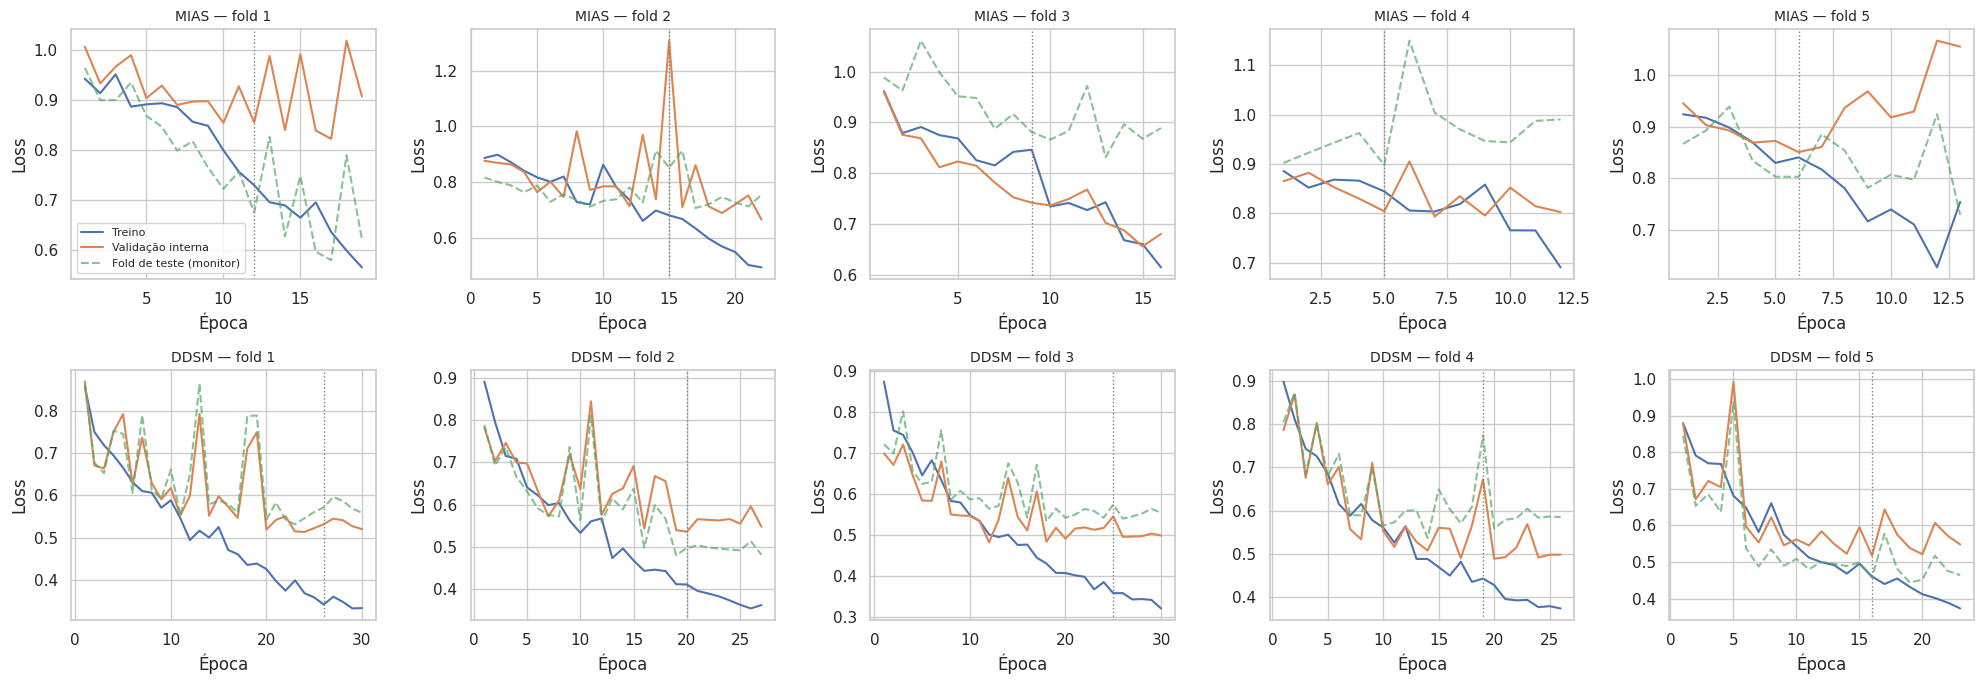

In [10]:
def run_experiment1(name, seed):
    d = DATA[name]
    X, y, g = d["X"], d["y"], d["groups"]
    outer = StratifiedGroupKFold(n_splits=CONFIG["N_SPLITS"], shuffle=True, random_state=seed)
    res = dict(folds=[], hist=[], oof=[])

    for fold, (tr_all, te) in enumerate(outer.split(X, y, g)):
        tr_in, va_in = group_holdout(y[tr_all], g[tr_all], seed + fold, CONFIG["INNER_VAL_FRAC"])
        tr, va = tr_all[tr_in], tr_all[va_in]
        # paciente em um só conjunto
        assert set(g[tr]).isdisjoint(g[va]) and set(g[tr]).isdisjoint(g[te]) and set(g[va]).isdisjoint(g[te])

        print(f"[{name}] fold {fold + 1}/{CONFIG['N_SPLITS']} | treino={len(tr)} val={len(va)} teste={len(te)}")
        model, hist = train_model(X, y, tr, va, seed + fold, mon_idx=te)

        p_va = predict_proba(model, X, y, va)
        thr = select_threshold(y[va], p_va)                  # limiar: validação interna
        p_te = predict_proba(model, X, y, te)
        m = compute_metrics(y[te], p_te, thr)

        b = hist.attrs["best_epoch"]
        row = hist[hist.epoch == b].iloc[0]
        m.update(dataset=name, fold=fold, best_epoch=b, gap_val_minus_train=row.val_loss - row.train_loss)
        res["folds"].append(m)
        res["hist"].append(hist)
        res["oof"].append(pd.DataFrame(dict(idx=te, y=y[te], p=p_te, pred=(p_te >= thr).astype(int),
                                            g=g[te], fold=fold)))
        print(f"  -> AUC={m['auc']:.3f} sens={m['sens']:.3f} spec={m['spec']:.3f} thr={thr:.3f}")
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    res["oof"] = pd.concat(res["oof"], ignore_index=True)
    return res


R1 = {}
for name in ["mias", "ddsm"]:
    R1[name] = run_experiment1(name, CONFIG["EXP1_SEED"])

with open(f"/content/drive/MyDrive/TCC/R1_dual_branch_{POOL_TAG}_clahe_ssf.pkl", "wb") as fh:
    pickle.dump(R1, fh)

# ---- Resumo: média ± dp entre folds ----
for name in ["mias", "ddsm"]:
    folds = pd.DataFrame(R1[name]["folds"])
    print(f"\n=== Experimento 1 — {name.upper()} (média ± dp entre {CONFIG['N_SPLITS']} folds) ===")
    display(mean_std_table(R1[name]["folds"]).to_frame("valor"))
    print(f"Gap Val − Treino (loss, na melhor época): "
          f"{folds.gap_val_minus_train.mean():.3f} ± {folds.gap_val_minus_train.std():.3f}")
    display(folds[["fold", "best_epoch", "auc", "sens", "spec", "bal_acc", "f1", "precision", "thr",
                   "gap_val_minus_train"]].round(3))
    folds.to_csv(OUT / f"exp1_folds_{name}.csv", index=False)

# ---- Curvas de loss ----
fig, axes = plt.subplots(2, CONFIG["N_SPLITS"], figsize=(4 * CONFIG["N_SPLITS"], 7), squeeze=False)
for r, name in enumerate(["mias", "ddsm"]):
    for f, h in enumerate(R1[name]["hist"]):
        ax = axes[r, f]
        ax.plot(h.epoch, h.train_loss, label="Treino")
        ax.plot(h.epoch, h.val_loss, label="Validação interna")
        ax.plot(h.epoch, h.mon_loss, "--", alpha=0.7, label="Fold de teste (monitor)")
        ax.axvline(h.attrs["best_epoch"], color="gray", ls=":", lw=1)
        ax.set_title(f"{name.upper()} — fold {f + 1}", fontsize=10)
        ax.set_xlabel("Época")
        ax.set_ylabel("Loss")
        if r == 0 and f == 0:
            ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "exp1_loss_curves.png", dpi=150)
plt.show()

## 7. Experimento 2: domain shift direto

Treina em um dataset e avalia no outro inteiro, nos dois sentidos (mias → ddsm e ddsm → mias). Para cada semente, a origem é dividida por paciente em treino e validação interna. O limiar vem só da origem. Nada do destino entra no treino, na escolha da época ou no limiar.

In [11]:
def run_experiment2(src, tgt):
    Xs, ys, gs = DATA[src]["X"], DATA[src]["y"], DATA[src]["groups"]
    Xt, yt = DATA[tgt]["X"], DATA[tgt]["y"]
    out = dict(probs={}, thr={}, metrics=[], src_val=[])

    for s in CONFIG["SEEDS"]:
        tr, va = group_holdout(ys, gs, s, CONFIG["INNER_VAL_FRAC"])
        assert set(gs[tr]).isdisjoint(gs[va])
        print(f"[{src} -> {tgt}] seed {s} | treino={len(tr)} val={len(va)} | alvo={len(yt)}")
        model, hist = train_model(Xs, ys, tr, va, s, mon_idx=None)

        p_va = predict_proba(model, Xs, ys, va)
        thr = select_threshold(ys[va], p_va)                          # limiar: origem
        p_t = predict_proba(model, Xt, yt, np.arange(len(yt)))        # alvo inteiro
        m = compute_metrics(yt, p_t, thr)
        m.update(seed=s, direction=f"{src}->{tgt}", best_epoch=hist.attrs["best_epoch"])
        out["metrics"].append(m)
        out["src_val"].append(compute_metrics(ys[va], p_va, thr))
        out["probs"][s], out["thr"][s] = p_t, thr
        print(f"  -> AUC alvo={m['auc']:.3f} sens={m['sens']:.3f} spec={m['spec']:.3f} thr(origem)={thr:.3f}")
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    return out


R2 = {}
for src, tgt in [("mias", "ddsm"), ("ddsm", "mias")]:
    R2[(src, tgt)] = run_experiment2(src, tgt)

with open(f"/content/drive/MyDrive/TCC/R2_dual_branch_{POOL_TAG}_clahe_ssf.pkl", "wb") as fh:
    pickle.dump(R2, fh)

for (src, tgt), r in R2.items():
    print(f"\n=== Experimento 2 — {src.upper()} → {tgt.upper()} ({len(CONFIG['SEEDS'])} sementes) ===")
    df = pd.DataFrame(r["metrics"])
    display(df[["seed", "best_epoch", "auc", "sens", "spec", "bal_acc", "f1", "precision", "thr"]].round(3))
    display(mean_std_table(r["metrics"]).to_frame("média ± dp"))
    df.to_csv(OUT / f"exp2_{src}_to_{tgt}.csv", index=False)

[mias -> ddsm] seed 42 | treino=273 val=45 | alvo=3716
  ep 01 | fase=ssf | LR=1.0e-03,3.0e-04,3.0e-04 | train 0.9756 | val 0.9436 | val AUC 0.613
  ep 02 | fase=ssf | LR=9.9e-04,3.0e-04,3.0e-04 | train 0.9007 | val 0.8855 | val AUC 0.654
  ep 03 | fase=ssf | LR=9.8e-04,2.9e-04,2.9e-04 | train 0.8750 | val 0.8349 | val AUC 0.744
  ep 04 | fase=ssf | LR=9.6e-04,2.9e-04,2.9e-04 | train 0.8836 | val 0.8324 | val AUC 0.800
  ep 05 | fase=ssf | LR=9.3e-04,2.8e-04,2.8e-04 | train 0.8318 | val 0.8790 | val AUC 0.754
  ep 06 | fase=ssf | LR=9.0e-04,2.7e-04,2.7e-04 | train 0.8485 | val 0.7643 | val AUC 0.809
  ep 07 | fase=ssf | LR=8.7e-04,2.6e-04,2.6e-04 | train 0.8012 | val 0.7496 | val AUC 0.845
  ep 08 | fase=ssf | LR=8.3e-04,2.5e-04,2.5e-04 | train 0.8423 | val 0.7855 | val AUC 0.830
  ep 09 | fase=ssf | LR=7.9e-04,2.4e-04,2.4e-04 | train 0.7888 | val 0.7788 | val AUC 0.782
  ep 10 | fase=ssf | LR=7.5e-04,2.3e-04,2.3e-04 | train 0.7488 | val 0.7441 | val AUC 0.809
  ep 11 | fase=ssf | LR=7

,seed,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr
0,42,19,0.651,0.339,0.845,0.592,0.417,0.543,0.703
1,123,12,0.616,0.346,0.831,0.588,0.418,0.526,0.381
2,999,23,0.655,0.550,0.674,0.612,0.512,0.478,0.400


,média ± dp
auc,0.641 ± 0.021
sens,0.412 ± 0.120
spec,0.783 ± 0.095
bal_acc,0.597 ± 0.013
f1,0.449 ± 0.054
precision,0.516 ± 0.033



=== Experimento 2 — DDSM → MIAS (3 sementes) ===


,seed,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr
0,42,21,0.829,0.613,0.850,0.731,0.648,0.687,0.336
1,123,4,0.706,0.505,0.826,0.665,0.552,0.609,0.383
2,999,19,0.778,0.586,0.870,0.728,0.640,0.707,0.398


,média ± dp
auc,0.771 ± 0.062
sens,0.568 ± 0.056
spec,0.849 ± 0.022
bal_acc,0.708 ± 0.037
f1,0.613 ± 0.053
precision,0.667 ± 0.052


## 8. Análise

- **Drop** = AUC interno (Exp. 1) − AUC cruzado (Exp. 2).
- **IC 95 %:** bootstrap que reamostra pacientes, não imagens.
- **Predição cruzada agregada:** média das probabilidades entre sementes e média dos limiares de origem.
- **Limiar "oráculo":** usa rótulos do alvo. Só diagnóstico, não reportar como desempenho.

In [12]:
# ---- Bootstrap por paciente ----
def patient_bootstrap(y, p, groups, n_boot, seed):
    rng = np.random.RandomState(seed)
    ug, inv = np.unique(groups, return_inverse=True)
    by_g = [np.where(inv == i)[0] for i in range(len(ug))]
    vals = []
    for _ in range(n_boot):
        pick = rng.randint(0, len(ug), len(ug))
        idx = np.concatenate([by_g[i] for i in pick])
        if len(np.unique(y[idx])) < 2:
            continue
        vals.append(roc_auc_score(y[idx], p[idx]))
    return np.array(vals)


def ci95(v):
    return np.percentile(v, [2.5, 97.5])


# ---- Predições internas (OOF) e cruzadas (ensemble) ----
OOF = {n: R1[n]["oof"] for n in ["mias", "ddsm"]}
CROSS = {}
for (src, tgt), r in R2.items():
    p_ens = np.mean([r["probs"][s] for s in CONFIG["SEEDS"]], axis=0)
    thr_ens = float(np.mean([r["thr"][s] for s in CONFIG["SEEDS"]]))
    CROSS[(src, tgt)] = dict(p=p_ens, thr=thr_ens, y=DATA[tgt]["y"], g=DATA[tgt]["groups"])

# ---- Tabela de generalização ----
rows = []
for (src, tgt) in R2:
    folds = pd.DataFrame(R1[src]["folds"])
    auc_int_fold = folds.auc.mean()
    o = OOF[src]
    auc_int_pool = roc_auc_score(o.y, o.p)
    b_int = patient_bootstrap(o.y.values, o.p.values, o.g.values, CONFIG["N_BOOT"], CONFIG["BOOT_SEED"])

    c = CROSS[(src, tgt)]
    seed_aucs = np.array([m["auc"] for m in R2[(src, tgt)]["metrics"]])
    auc_cross_ens = roc_auc_score(c["y"], c["p"])
    b_cr = patient_bootstrap(c["y"], c["p"], c["g"], CONFIG["N_BOOT"], CONFIG["BOOT_SEED"] + 1)

    m = min(len(b_int), len(b_cr))
    b_drop = b_int[:m] - b_cr[:m]
    drop_seed = auc_int_fold - seed_aucs
    lo_i, hi_i = ci95(b_int)
    lo_c, hi_c = ci95(b_cr)
    lo_d, hi_d = ci95(b_drop)
    rows.append({
        "Sentido": f"{src.upper()} → {tgt.upper()}",
        "AUC interno (média folds ± dp)": f"{auc_int_fold:.3f} ± {folds.auc.std():.3f}",
        "AUC interno OOF [IC95%]": f"{auc_int_pool:.3f} [{lo_i:.3f}, {hi_i:.3f}]",
        "AUC cruzado (sementes ± dp)": f"{seed_aucs.mean():.3f} ± {seed_aucs.std(ddof=1) if len(seed_aucs) > 1 else 0:.3f}",
        "AUC cruzado ensemble [IC95%]": f"{auc_cross_ens:.3f} [{lo_c:.3f}, {hi_c:.3f}]",
        "Drop (média folds − sementes ± dp)": f"{drop_seed.mean():.3f} ± {drop_seed.std(ddof=1) if len(drop_seed) > 1 else 0:.3f}",
        "Drop (OOF − ensemble) [IC95%]": f"{auc_int_pool - auc_cross_ens:.3f} [{lo_d:.3f}, {hi_d:.3f}]",
    })
gen_table = pd.DataFrame(rows).set_index("Sentido")
display(gen_table.T)
gen_table.to_csv(OUT / "generalization_summary.csv")

Sentido,MIAS → DDSM,DDSM → MIAS
AUC interno (média folds ± dp),0.719 ± 0.112,0.910 ± 0.010
AUC interno OOF [IC95%],"0.719 [0.656, 0.777]","0.895 [0.882, 0.908]"
AUC cruzado (sementes ± dp),0.641 ± 0.021,0.771 ± 0.062
AUC cruzado ensemble [IC95%],"0.656 [0.632, 0.678]","0.800 [0.746, 0.850]"
Drop (média folds − sementes ± dp),0.079 ± 0.021,0.138 ± 0.062
Drop (OOF − ensemble) [IC95%],"0.063 [-0.003, 0.125]","0.095 [0.042, 0.149]"


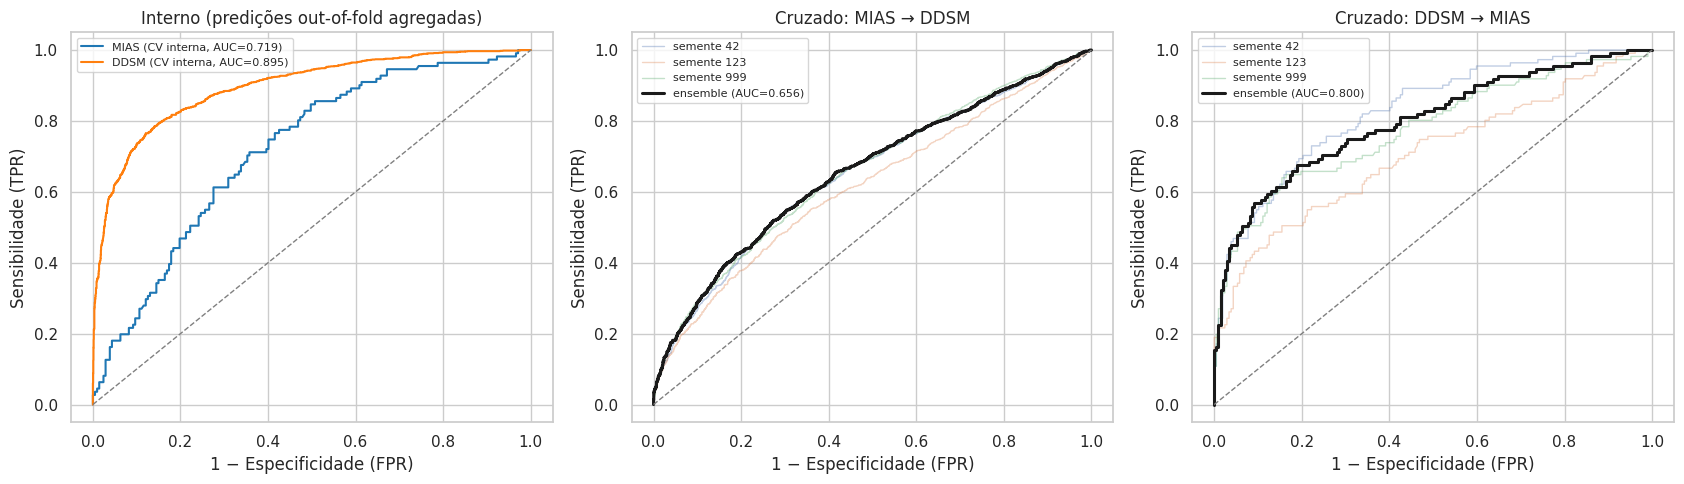

In [13]:
# ---- Curvas ROC ----
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ax = axes[0]
for n, col in [("mias", "tab:blue"), ("ddsm", "tab:orange")]:
    o = OOF[n]
    fpr, tpr, _ = roc_curve(o.y, o.p)
    ax.plot(fpr, tpr, color=col, label=f"{n.upper()} (CV interna, AUC={roc_auc_score(o.y, o.p):.3f})")
ax.set_title("Interno (predições out-of-fold agregadas)")

for ax, (src, tgt) in zip(axes[1:], R2):
    c = CROSS[(src, tgt)]
    for s in CONFIG["SEEDS"]:
        fpr, tpr, _ = roc_curve(c["y"], R2[(src, tgt)]["probs"][s])
        ax.plot(fpr, tpr, alpha=0.35, lw=1, label=f"semente {s}")
    fpr, tpr, _ = roc_curve(c["y"], c["p"])
    ax.plot(fpr, tpr, "k", lw=2.2, label=f"ensemble (AUC={roc_auc_score(c['y'], c['p']):.3f})")
    ax.set_title(f"Cruzado: {src.upper()} → {tgt.upper()}")

for ax in axes:
    ax.plot([0, 1], [0, 1], "--", color="gray", lw=1)
    ax.set_xlabel("1 − Especificidade (FPR)")
    ax.set_ylabel("Sensibilidade (TPR)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "roc_curves.png", dpi=150)
plt.show()

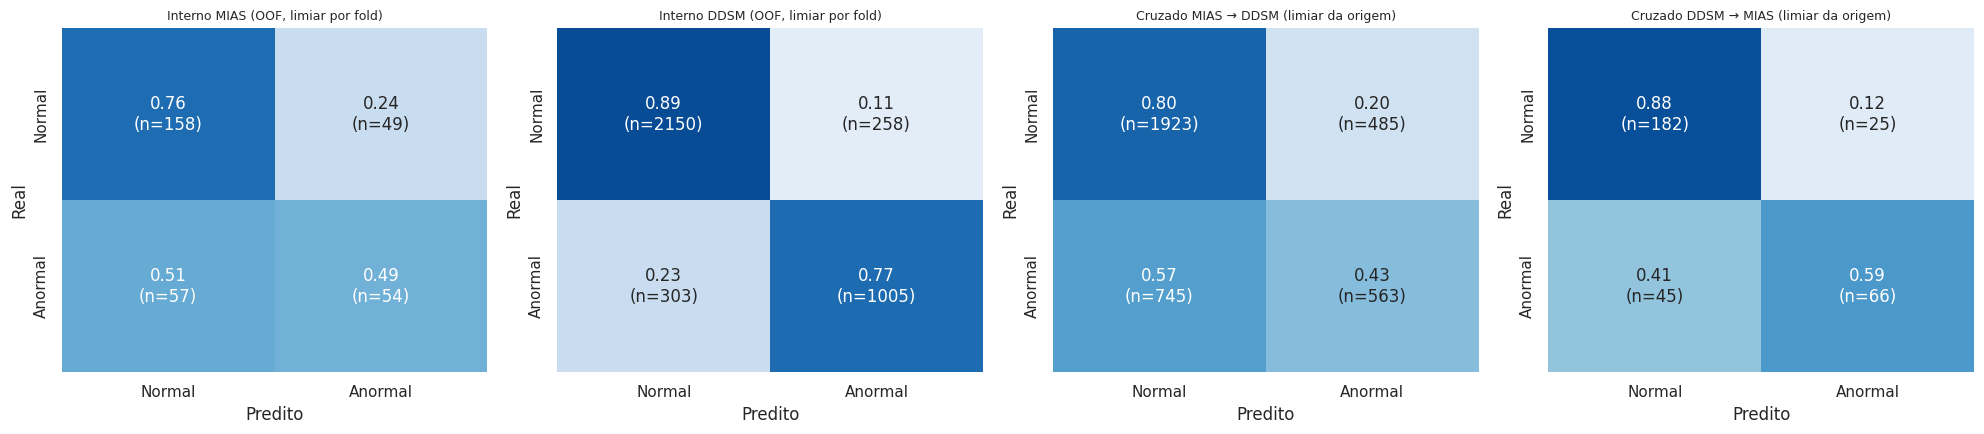

In [14]:
# ---- Matrizes de confusão ----
panels = [(f"Interno {n.upper()} (OOF, limiar por fold)", OOF[n].y.values, OOF[n].pred.values) for n in OOF]
panels += [(f"Cruzado {s.upper()} → {t.upper()} (limiar da origem)", CROSS[(s, t)]["y"],
            (CROSS[(s, t)]["p"] >= CROSS[(s, t)]["thr"]).astype(int)) for (s, t) in R2]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (title, yt_, yp_) in zip(axes, panels):
    cm = confusion_matrix(yt_, yp_, labels=[0, 1])
    cmn = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cmn[i, j]:.2f}\n(n={cm[i, j]})" for j in range(2)] for i in range(2)])
    sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=["Normal", "Anormal"], yticklabels=["Normal", "Anormal"])
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("Predito")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.savefig(OUT / "confusion_matrices.png", dpi=150)
plt.show()

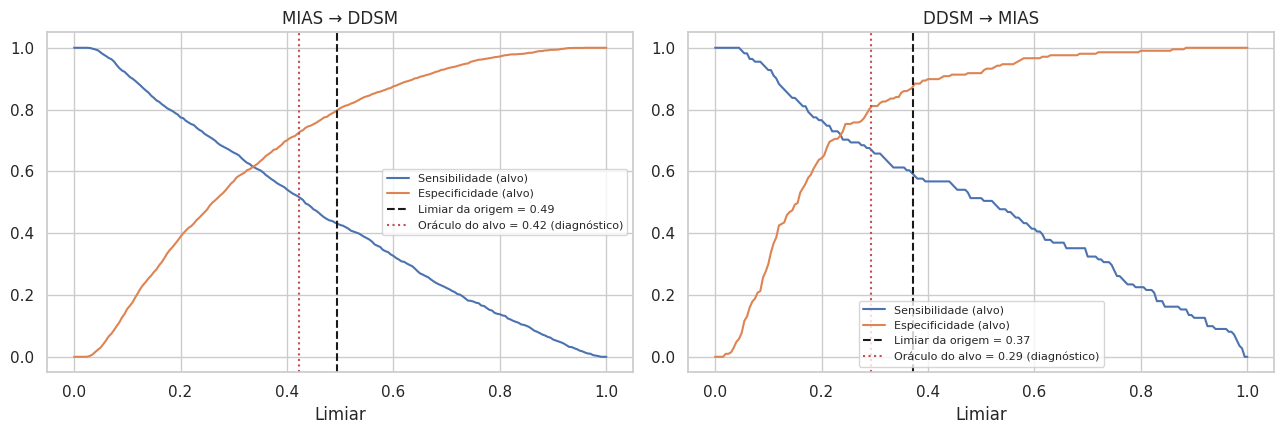

Sentido,MIAS → DDSM,DDSM → MIAS
Sens interna (origem),0.501,0.769
Esp interna (origem),0.765,0.893
Sens alvo @limiar origem,0.430,0.595
Esp alvo @limiar origem,0.799,0.879
Sens alvo @oráculo (diag.),0.519,0.676
Esp alvo @oráculo (diag.),0.726,0.812
Δ Sens (alvo − interna),-0.071,-0.174
Δ Esp (alvo − interna),0.034,-0.014



Arquivos salvos em: /content/drive/MyDrive/TCC/outputs_dual_branch_clahe_roi_ssf_db4_haar


In [15]:
# ---- Deslocamento de limiar ----
ths = np.linspace(0, 1, 201)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
shift_rows = []
for ax, (src, tgt) in zip(axes, R2):
    c = CROSS[(src, tgt)]
    sens = [((c["p"] >= t) & (c["y"] == 1)).sum() / (c["y"] == 1).sum() for t in ths]
    spec = [((c["p"] < t) & (c["y"] == 0)).sum() / (c["y"] == 0).sum() for t in ths]
    ax.plot(ths, sens, label="Sensibilidade (alvo)")
    ax.plot(ths, spec, label="Especificidade (alvo)")
    ax.axvline(c["thr"], color="k", ls="--", label=f"Limiar da origem = {c['thr']:.2f}")
    t_or = select_threshold(c["y"], c["p"], "youden")   # só diagnóstico
    ax.axvline(t_or, color="r", ls=":", label=f"Oráculo do alvo = {t_or:.2f} (diagnóstico)")
    ax.set_title(f"{src.upper()} → {tgt.upper()}")
    ax.set_xlabel("Limiar")
    ax.legend(fontsize=8)

    internal = pd.DataFrame(R1[src]["folds"])
    mo = compute_metrics(c["y"], c["p"], c["thr"])
    mc = compute_metrics(c["y"], c["p"], t_or)
    shift_rows.append({"Sentido": f"{src.upper()} → {tgt.upper()}",
                       "Sens interna (origem)": internal.sens.mean(), "Esp interna (origem)": internal.spec.mean(),
                       "Sens alvo @limiar origem": mo["sens"], "Esp alvo @limiar origem": mo["spec"],
                       "Sens alvo @oráculo (diag.)": mc["sens"], "Esp alvo @oráculo (diag.)": mc["spec"]})
plt.tight_layout()
plt.savefig(OUT / "threshold_shift.png", dpi=150)
plt.show()

shift = pd.DataFrame(shift_rows).set_index("Sentido").round(3)
shift["Δ Sens (alvo − interna)"] = shift["Sens alvo @limiar origem"] - shift["Sens interna (origem)"]
shift["Δ Esp (alvo − interna)"] = shift["Esp alvo @limiar origem"] - shift["Esp interna (origem)"]
display(shift.T.round(3))
shift.to_csv(OUT / "threshold_shift.csv")
print(f"\nArquivos salvos em: {OUT.resolve()}")

## 9. Resumo das métricas

| Métrica | O que mede | Quando usar |
|---|---|---|
| **Acurácia** | Proporção de acertos gerais | Dados balanceados |
| **Precisão** | Confiabilidade das predições positivas | Evitar falsos positivos |
| **Recall** (sensibilidade) | Capacidade de encontrar positivos reais | Evitar falsos negativos |
| **F1-score** | Equilíbrio entre precisão e recall | Dados desbalanceados |
| **AUC-ROC** | Capacidade de separar as classes | Avaliação global do modelo |


In [16]:
# média ± dp entre folds (Exp. 1) ou sementes (Exp. 2)
COLS = {"acc": "Acurácia", "precision": "Precisão", "sens": "Recall", "f1": "F1-score", "auc": "AUC-ROC"}


def fmt(rows):
    df = pd.DataFrame(rows)[list(COLS)]
    return {v: f"{df[k].mean():.3f} ± {df[k].std():.3f}" for k, v in COLS.items()}


summary = {f"Exp. 1 — {n.upper()} (CV)": fmt(R1[n]["folds"]) for n in ["mias", "ddsm"]}
summary.update({f"Exp. 2 — {s.upper()} → {t.upper()}": fmt(r["metrics"]) for (s, t), r in R2.items()})
summary = pd.DataFrame(summary).T
display(summary)
summary.to_csv(OUT / "final_summary.csv")

,Acurácia,Precisão,Recall,F1-score,AUC-ROC
Exp. 1 — MIAS (CV),0.666 ± 0.083,0.539 ± 0.144,0.501 ± 0.166,0.506 ± 0.108,0.719 ± 0.112
Exp. 1 — DDSM (CV),0.849 ± 0.016,0.798 ± 0.037,0.769 ± 0.030,0.782 ± 0.017,0.910 ± 0.010
Exp. 2 — MIAS → DDSM,0.652 ± 0.019,0.516 ± 0.033,0.412 ± 0.120,0.449 ± 0.054,0.641 ± 0.021
Exp. 2 — DDSM → MIAS,0.751 ± 0.032,0.667 ± 0.052,0.568 ± 0.056,0.613 ± 0.053,0.771 ± 0.062
